# 03 · Fairness audit: who bears the false positives?

A false positive in account opening is a **legitimate person denied a bank account** or
put through extra checks. If those errors fall much more often on one group, the model
is unfair to that group, even if it is accurate on average. This notebook audits the
model from notebook 02 across **age groups**, explains where a disparity comes from, and
compares ways to reduce it, together with what each one costs in fraud caught.

### Fairness, in three common definitions

| Criterion | Asks for equal… | Here it means |
|---|---|---|
| Demographic parity | flag rate | each group flagged equally often, whatever its fraud rate |
| Equal opportunity | true-positive rate | fraudsters caught equally often in each group |
| **Predictive equality** | **false-positive rate** | **legitimate applicants wrongly flagged equally often** |

We focus on **predictive equality**: the harm we worry about falls on legitimate
applicants, and it is the criterion used in the BAF paper. A common yardstick is the
**"four-fifths" (80 %) rule**, under which the ratio of the lower to the higher error rate
should be at least 0.8.

One result to keep in mind: when groups have **different fraud rates** (notebook 01: 0.9 %
under 50, 2.6 % for 50+), no classifier can satisfy all criteria at once, except a perfect
one (Kleinberg et al. 2016; Chouldechova 2017). Choosing a criterion is a value
judgement, not a technical one.

**Protocol.** As in the BAF paper, groups are applicants under 50 vs. 50 and over, and
every policy is compared at exactly **5 % overall FPR on the test months**. This
separates fairness from the threshold drift handled in notebook 02. Section 7 then checks
the realistic case, with thresholds set in advance.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import roc_auc_score

from fraudkit import baf
from fraudkit.fairness import (
    group_rates, group_thresholds_at_fpr, rates, recall_at_fpr, threshold_at_fpr,
)
from fraudkit.metrics import wilson_interval
from fraudkit.plotting import CLASS_COLORS, INK_2, MUTED, SERIES, finish, label_bars, set_style

set_style()
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.4f}".format)
FPR = 0.05
GROUP_COLORS = {"<50": SERIES[0], "50+": SERIES[2]}

df = baf.load()
FEATURES = baf.features(df)
NO_AGE = baf.features(df, drop_protected=True)
y, month = df.fraud_bool.values, df.month.values
TRAIN_FULL, TEST = month <= 5, month >= 6
y_te, g_te = y[TEST], df.age_group.values[TEST]

# Same model as notebook 02: refit on months 0–5 with the rounds found by early stopping.
early = baf.fit(df, month <= 4, FEATURES, 5000, valid_rows=month == 5, early_stopping=200)
ROUNDS = int(early.best_iteration * TRAIN_FULL.sum() / (month <= 4).sum())
model = baf.fit(df, TRAIN_FULL, FEATURES, ROUNDS)
s_te = baf.predict(model, df, TEST, FEATURES)
print(f"{ROUNDS} rounds · test recall @ 5 % FPR {recall_at_fpr(y_te, s_te, FPR):.3f}")

/home/newf/projects/fraud-detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


361 rounds · test recall @ 5 % FPR 0.545


## 1. The audit

One threshold for everybody, set so that 5 % of all legitimate test applicants are
flagged. How are the errors distributed?

In [2]:
t_global = threshold_at_fpr(y_te, s_te, FPR)
flag_global = s_te >= t_global
audit = group_rates(y_te, flag_global, g_te).loc[["<50", "50+"]]


def fpr_ratio_ci(y_, flagged, groups, n_boot=500, seed=0):
    """Bootstrap interval for min(FPR)/max(FPR) across groups."""
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_), len(y_))
        g = group_rates(y_[i], flagged[i], groups[i])
        out.append(g.FPR.min() / g.FPR.max())
    return np.quantile(out, [0.025, 0.975])


ratio_lo, ratio_hi = fpr_ratio_ci(y_te, flag_global, g_te)
print(f"FPR ratio (<50 vs 50+): {audit.FPR.min() / audit.FPR.max():.2f}  (95 % CI {ratio_lo:.2f}–{ratio_hi:.2f})")
audit[["n", "prevalence", "flag rate", "TPR", "FPR"]]

FPR ratio (<50 vs 50+): 0.33  (95 % CI 0.32–0.34)


,n,prevalence,flag rate,TPR,FPR
<50,"171,232.0000",0.0110,0.0425,0.4743,0.0377
50+,"33,779.0000",0.0293,0.1303,0.6795,0.1137


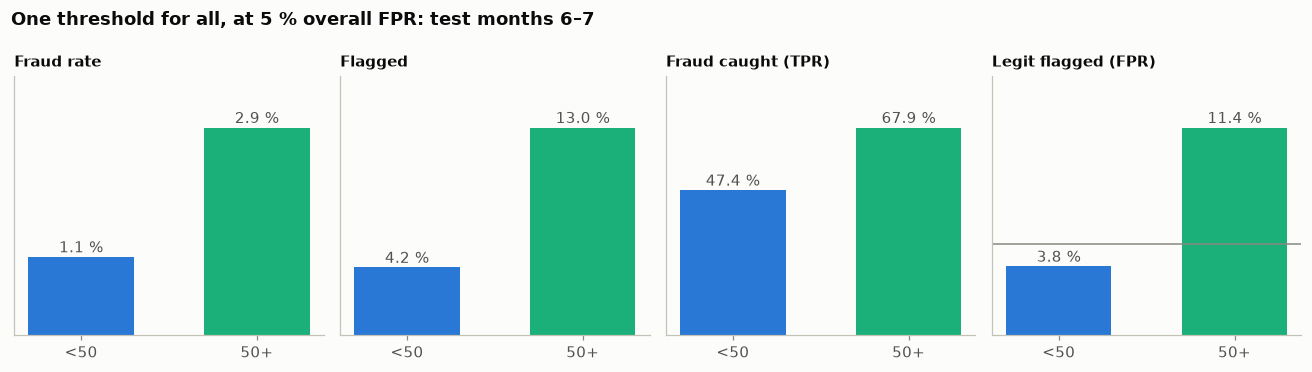

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, (col, title) in zip(axes, [("prevalence", "Fraud rate"), ("flag rate", "Flagged"),
                                   ("TPR", "Fraud caught (TPR)"), ("FPR", "Legit flagged (FPR)")]):
    bars = ax.bar(audit.index, audit[col] * 100, color=[GROUP_COLORS[g] for g in audit.index], width=0.6)
    label_bars(ax, bars, fmt="{:.1f} %")
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, audit[col].max() * 100 * 1.25)
    ax.grid(axis="x", visible=False); ax.set_yticks([])
axes[3].axhline(FPR * 100, color=MUTED, lw=1)
fig.suptitle("One threshold for all, at 5 % overall FPR: test months 6–7", x=0.01, ha="left", fontweight="bold")
finish(fig)

**Reading it.** With one threshold for everyone, **legitimate applicants aged 50+ are
flagged 11.4 % of the time, three times the 3.8 % for under-50s**. The FPR ratio is
**0.33** (95 % CI 0.32–0.34), far below the 0.8 yardstick. In exchange, the model
catches more of the older group's fraud (68 % vs 47 %). The higher fraud rate among older
applicants (2.9 % vs 1.1 %) pushes their whole score distribution up, legitimate
applicants included.

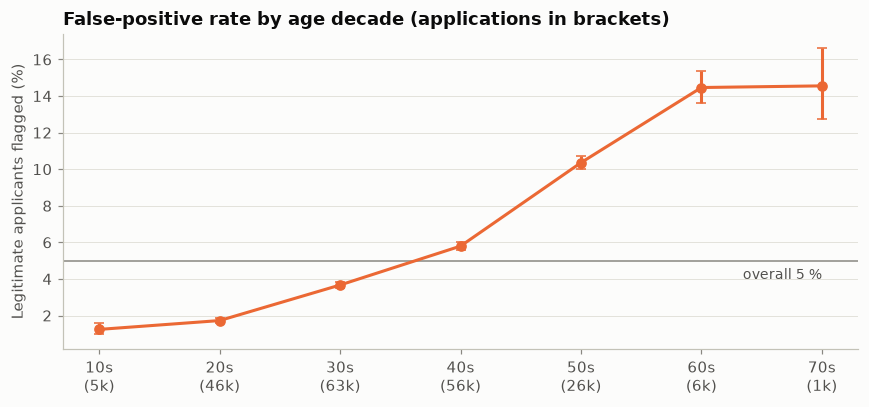

In [4]:
by_age = group_rates(y_te, flag_global, df.customer_age.values[TEST])
by_age = by_age[by_age.n >= 1000]
legit_n = (by_age.n * (1 - by_age.prevalence)).astype(int)
fp = (by_age.FPR * legit_n).round().astype(int)
lo, hi = wilson_interval(fp, legit_n)
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(by_age))
ax.errorbar(x, by_age.FPR * 100, yerr=[(by_age.FPR - lo) * 100, (hi - by_age.FPR) * 100],
            color=SERIES[1], marker="o", capsize=3, lw=2)
ax.axhline(FPR * 100, color=MUTED, lw=1)
ax.annotate("overall 5 %", (x[-1], FPR * 100), xytext=(0, -12), textcoords="offset points", ha="right",
            color=INK_2, fontsize=9)
ax.set_xticks(x, [f"{int(a)}s\n({n / 1000:,.0f}k)" for a, n in zip(by_age.index, by_age.n)])
ax.set_ylabel("Legitimate applicants flagged (%)")
ax.set_title("False-positive rate by age decade (applications in brackets)")
ax.grid(axis="x", visible=False)
finish(fig)

**Reading it.** The disparity grows steadily with age: about 1–2 % of legitimate
applicants in their teens and 20s are flagged, 10 % in their 50s and over 14 % in their
60s and 70s, about ten times the youngest groups. The 70s are a small group (1,000
applications), hence the wider interval.

## 2. Where does the gap come from?

The model ranks applicants by score, so the question is why *legitimate* older applicants
score higher. SHAP can answer it: for legitimate applicants only, compare each feature's
average contribution in the 50+ group with the <50 group. Features with a large positive
difference are the ones pushing older legitimate applicants towards the threshold.

average score gap, legit 50+ minus legit <50: +0.75 log-odds


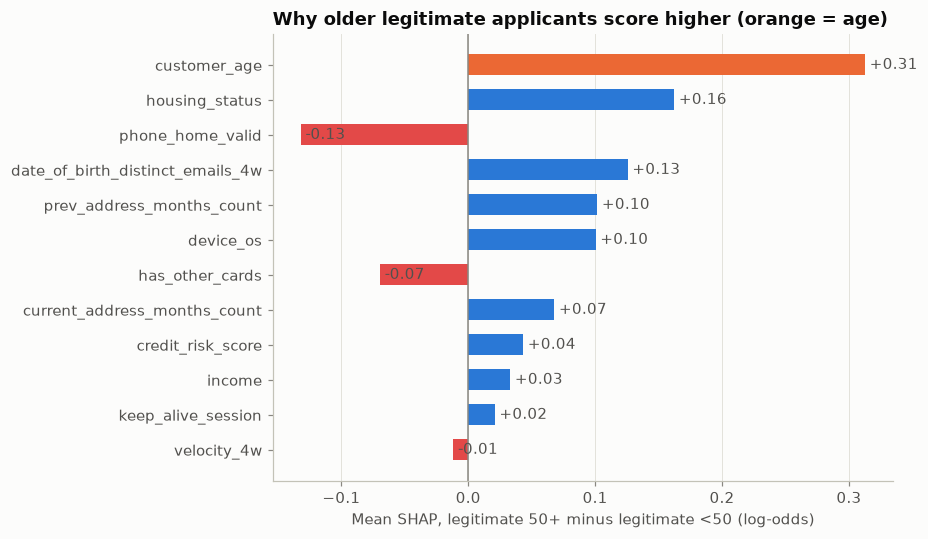

In [5]:
rng = np.random.default_rng(0)
te_rows = np.where(TEST)[0]
legit_old = rng.choice(te_rows[(y_te == 0) & (g_te == "50+")], 8000, replace=False)
legit_young = rng.choice(te_rows[(y_te == 0) & (g_te == "<50")], 8000, replace=False)
mask = np.zeros(len(df), bool); mask[np.r_[legit_old, legit_young]] = True
X_s, _ = baf.matrix(df, FEATURES, mask)
sv = shap.TreeExplainer(model)(pd.DataFrame(X_s, columns=FEATURES))
vals = sv.values if sv.values.ndim == 2 else sv.values[..., 1]
is_old = (df.age_group.values[mask] == "50+")
gap = pd.Series(vals[is_old].mean(axis=0) - vals[~is_old].mean(axis=0), index=FEATURES)
total = gap.sum()
print(f"average score gap, legit 50+ minus legit <50: {total:+.2f} log-odds")
top_gap = gap.reindex(gap.abs().sort_values().index)[-12:]

fig, ax = plt.subplots(figsize=(8.5, 5))
bars = ax.barh(top_gap.index, top_gap.values, height=0.6,
               color=[SERIES[1] if f == baf.PROTECTED else (SERIES[0] if v > 0 else SERIES[7])
                      for f, v in zip(top_gap.index, top_gap.values)])
label_bars(ax, bars, fmt="{:+.2f}", horizontal=True)
ax.axvline(0, color=MUTED, lw=1)
ax.set_xlabel("Mean SHAP, legitimate 50+ minus legitimate <50 (log-odds)")
ax.set_title("Why older legitimate applicants score higher (orange = age)")
ax.grid(axis="y", visible=False)
finish(fig)

**Reading it.** Legitimate 50+ applicants score on average **+0.75 log-odds** higher
than legitimate under-50s. The `customer_age` column itself contributes **+0.31**, about
40 %. The rest arrives through other features: housing status, the number of e-mails
used with the same date of birth, a missing previous address and the device. Some
features pull the other way: older applicants more often have a valid home phone and
other cards, which lowers their scores. **Most of the gap doesn't come from the age
column**, which predicts what the next experiment shows.

## 3. Mitigation A: "fairness through unawareness"

The intuitive fix is to remove the protected attribute from the model. It only works if
no other feature carries the same information. First, how well can the *other* features
predict whether an applicant is 50+?

In [6]:
proxy = baf.fit(df.assign(fraud_bool=(df.customer_age >= 50).astype("int8")), month <= 4, NO_AGE, 300)
proxy_auc = roc_auc_score(df.customer_age[TEST] >= 50, baf.predict(proxy, df, TEST, NO_AGE))
print(f"age 50+ predicted from the other features: ROC-AUC {proxy_auc:.3f}")

model_na = baf.fit(df, TRAIN_FULL, NO_AGE, ROUNDS)
s_na = baf.predict(model_na, df, TEST, NO_AGE)
flag_na = s_na >= threshold_at_fpr(y_te, s_na, FPR)
audit_na = group_rates(y_te, flag_na, g_te).loc[["<50", "50+"]]
audit_na[["TPR", "FPR"]]

age 50+ predicted from the other features: ROC-AUC 0.839


,TPR,FPR
<50,0.5003,0.0412
50+,0.6380,0.0954


**Reading it.** The other features predict "50+" with **ROC-AUC 0.84**: age is
substantially recoverable from them. Removing the column helps a little: the 50+ FPR falls
from 11.4 % to 9.5 %, and the ratio improves from 0.33 to 0.43, at no cost in recall
(0.548 vs 0.545). But the result is still far from 0.8. **Unawareness isn't fairness**
when proxies exist.

## 4. Mitigation B: group-specific thresholds

A post-processing fix: keep the model, but use one threshold per group, each set so that
the group's FPR is 5 %. Predictive equality then holds by construction, and the overall
FPR stays at 5 %. The question is what it costs in fraud caught.

In [7]:
th = group_thresholds_at_fpr(y_te, s_te, g_te, FPR)
flag_group = s_te >= np.vectorize(th.get)(g_te)
audit_g = group_rates(y_te, flag_group, g_te).loc[["<50", "50+"]]
print("thresholds:", {k: round(v, 4) for k, v in th.items()}, f"(global {t_global:.4f})")
audit_g[["TPR", "FPR", "flag rate"]]

thresholds: {'50+': 0.0903, '<50': 0.0313} (global 0.0402)


,TPR,FPR,flag rate
<50,0.5304,0.0500,0.0553
50+,0.4975,0.0500,0.0631


## 5. The trade-off between fairness and fraud caught

Between "one threshold" and "full parity" lies a continuum. We fix the overall FPR at 5 %
and gradually lower the 50+ group's FPR, raising the <50 group's accordingly, and record
the FPR ratio and the overall recall at each step.

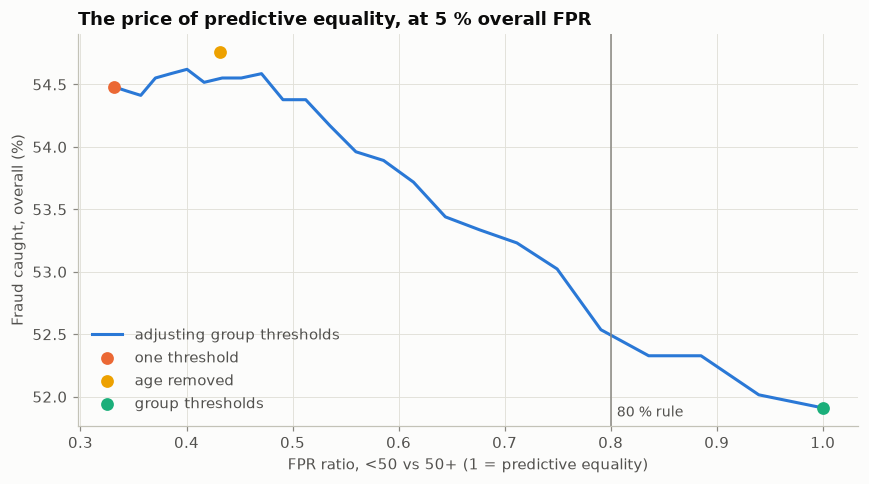

In [8]:
legit = y_te == 0
n_old, n_young = (legit & (g_te == "50+")).sum(), (legit & (g_te == "<50")).sum()
old_s, young_s = s_te[g_te == "50+"], s_te[g_te == "<50"]
old_y, young_y = y_te[g_te == "50+"], y_te[g_te == "<50"]
fpr_old_start = audit.loc["50+", "FPR"]
curve = []
for f_old in np.linspace(fpr_old_start, FPR, 25):
    f_young = (FPR * (n_old + n_young) - f_old * n_old) / n_young   # keeps overall FPR at 5 %
    t_old, t_young = threshold_at_fpr(old_y, old_s, f_old), threshold_at_fpr(young_y, young_s, f_young)
    flagged = np.where(g_te == "50+", s_te >= t_old, s_te >= t_young)
    r_ = group_rates(y_te, flagged, g_te)
    curve.append({"FPR 50+": r_.loc["50+", "FPR"], "FPR <50": r_.loc["<50", "FPR"],
                  "FPR ratio": r_.FPR.min() / r_.FPR.max(), "recall": rates(y_te, flagged)["TPR"],
                  "TPR 50+": r_.loc["50+", "TPR"], "TPR <50": r_.loc["<50", "TPR"]})
curve = pd.DataFrame(curve)

points = {
    "one threshold": (audit.FPR.min() / audit.FPR.max(), rates(y_te, flag_global)["TPR"]),
    "age removed": (audit_na.FPR.min() / audit_na.FPR.max(), rates(y_te, flag_na)["TPR"]),
    "group thresholds": (audit_g.FPR.min() / audit_g.FPR.max(), rates(y_te, flag_group)["TPR"]),
}
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curve["FPR ratio"], curve.recall * 100, color=SERIES[0], lw=2, label="adjusting group thresholds")
for (name, (xr, yr)), color in zip(points.items(), [SERIES[1], SERIES[3], SERIES[2]]):
    ax.scatter([xr], [yr * 100], color=color, s=70, zorder=3, edgecolor="white", label=name)
ax.axvline(0.8, color=MUTED, lw=1)
ax.annotate("80 % rule", (0.8, ax.get_ylim()[0]), xytext=(4, 6), textcoords="offset points", color=INK_2, fontsize=9)
ax.set_xlabel("FPR ratio, <50 vs 50+ (1 = predictive equality)")
ax.set_ylabel("Fraud caught, overall (%)")
ax.set_title("The price of predictive equality, at 5 % overall FPR")
ax.legend(loc="lower left")
finish(fig)

**Reading it.** (The vertical axis is zoomed: the whole curve spans under 3 points of
recall.)
* **The first steps are free.** The FPR ratio can rise from 0.33 to about 0.47 with no
  loss of recall. Removing the age column lands in this flat region too.
* **Meeting the 80 % rule costs about 2 points of recall** (54.5 % → 52.5 %).
* **Full predictive equality costs 2.6 points** (54.5 % → 51.9 %): the 50+ group's FPR
  falls from 11.4 % to 5 %, the under-50 group's rises from 3.8 % to 5 %, and fewer
  older fraudsters are caught (TPR 68 % → 50 %).

How much recall a fairness gain is worth is a business and ethical decision. The curve
gives decision-makers the menu.

In [9]:
summary = pd.DataFrame({
    name: {"FPR <50": a.loc["<50", "FPR"], "FPR 50+": a.loc["50+", "FPR"],
           "FPR ratio": a.FPR.min() / a.FPR.max(),
           "TPR <50": a.loc["<50", "TPR"], "TPR 50+": a.loc["50+", "TPR"],
           "recall overall": rates(y_te, f)["TPR"]}
    for name, a, f in [("one threshold", audit, flag_global), ("age removed", audit_na, flag_na),
                       ("group thresholds", audit_g, flag_group)]
}).T
summary

,FPR <50,FPR 50+,FPR ratio,TPR <50,TPR 50+,recall overall
one threshold,0.0377,0.1137,0.3312,0.4743,0.6795,0.5448
age removed,0.0412,0.0954,0.4320,0.5003,0.6380,0.5476
group thresholds,0.0500,0.0500,0.9998,0.5304,0.4975,0.5191


## 6. Does it hold when thresholds are set in advance?

Above, thresholds were set on the test months themselves, as in the paper's protocol. In
production they come from the past. Here the model is trained on months 0–4, both global
and group thresholds are set on month 5, and both are applied unchanged to months 6–7.

In [10]:
s_val = baf.predict(early, df, month == 5, FEATURES)
s_te_early = baf.predict(early, df, TEST, FEATURES)
g_val, y_val = df.age_group.values[month == 5], y[month == 5]
t_val = threshold_at_fpr(y_val, s_val, FPR)
th_val = group_thresholds_at_fpr(y_val, s_val, g_val, FPR)
rows = []
for name, flagged in [("one threshold", s_te_early >= t_val),
                      ("group thresholds", s_te_early >= np.vectorize(th_val.get)(g_te))]:
    r_ = group_rates(y_te, flagged, g_te)
    rows.append({"policy": name, "FPR <50": r_.loc["<50", "FPR"], "FPR 50+": r_.loc["50+", "FPR"],
                 "FPR ratio": r_.FPR.min() / r_.FPR.max(), "overall FPR": rates(y_te, flagged)["FPR"],
                 "recall": rates(y_te, flagged)["TPR"]})
pd.DataFrame(rows).set_index("policy")

,FPR <50,FPR 50+,FPR ratio,overall FPR,recall
policy,,,,,
one threshold,0.0438,0.1412,0.3105,0.0596,0.5841
group thresholds,0.0595,0.0650,0.9157,0.0604,0.5549


**Reading it.** Set in advance on month 5, the group thresholds still deliver a ratio of
**0.92** in months 6–7 (FPR 6.0 % vs 6.5 %), against 0.31 for a single threshold. Both
policies overshoot the 5 % overall target (≈ 6.0 %): that is the threshold drift from
notebook 02, which is independent of the fairness fix. In production the two
remedies combine: per-group *flag-rate* quantiles, refreshed frequently.

## 7. Discussion and conclusions

| Policy (5 % overall FPR, test months) | FPR <50 | FPR 50+ | FPR ratio | Fraud caught |
|---|---|---|---|---|
| One threshold | 3.8 % | 11.4 % | 0.33 | 54.5 % |
| Age column removed | 4.1 % | 9.5 % | 0.43 | 54.8 % |
| Group thresholds | 5.0 % | 5.0 % | 1.00 | 51.9 % |

**What we learned**
* **A model can be accurate and still unequal.** Legitimate applicants aged 50+ are
  three times as likely to be wrongly flagged. The cause is real: fraud *is* more common
  among older identities. But the cost lands on innocent older applicants.
* **Removing the protected attribute isn't enough.** Other features predict age (AUC
  0.84) and carry ~60 % of the score gap.
* **Post-processing with group thresholds closes the gap** and holds up reasonably when
  set in advance. It costs 2.6 points of recall for full parity, and about 2 points for the
  80 % rule.

**Caveats a real deployment would need to weigh**
* **Legal constraints.** Group thresholds use age *at decision time*, which is explicit
  disparate treatment and may be prohibited in some jurisdictions or products, even when
  the aim is to reduce disparate impact. Alternatives that don't use age at decision time
  include **in-processing** (training with a fairness constraint, e.g. Fairlearn's
  reductions), **re-weighting** the training data, or removing or transforming the strongest
  proxies. All of these need legal and compliance input.
* **The criterion is a choice.** We equalised false-positive rates. Equalising true-positive
  rates or flag rates would lead to different policies, and with different fraud rates
  they cannot all hold at once.
* **Groups are coarse.** One binary split on one attribute. A real audit would cover income
  and employment, their intersections, and small groups with too little data for
  reliable rates.
* **Synthetic data.** BAF mimics real application data, including its biases, but the
  numbers illustrate a method rather than any real bank's model.